In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [64]:
beaufort_scale = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-04-14/beaufort_scale.csv')
birds = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-04-14/birds.csv')
sea_states = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-04-14/sea_states.csv')
ships = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-04-14/ships.csv')

C:\Users\user\AppData\Local\Temp\ipykernel_43888\1784095987.py:2: DtypeWarning: Columns (0: sex) have mixed types. Specify dtype option on import or set low_memory=False.
  birds = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-04-14/birds.csv')


In [65]:
dataframes = {
    "beaufort_scale": beaufort_scale,
    "birds": birds,
    "sea_states": sea_states,
    "ships": ships
}

for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print("Missing values per column:")
    print(df.isna().sum())
    print("Duplicate rows:", df.duplicated().sum())


--- beaufort_scale ---
Missing values per column:
wind_speed_class        0
wind_description        0
wind_speed_knots_min    0
wind_speed_knots_max    1
dtype: int64
Duplicate rows: 0

--- birds ---
Missing values per column:
bird_observation_id            0
record_id                      0
species_common_name          691
species_scientific_name     1101
species_abbreviation         691
age                        38837
wan_plumage_phase          39444
plumage_phase              48938
sex                        49015
count                       2699
n_feeding                  26448
feeding                    21095
n_sitting_on_water         26448
sitting_on_water           21122
n_sitting_on_ice           26448
sitting_on_ice             21131
sitting_on_ship            21132
in_hand                    21133
n_flying_past              26448
flying_past                21128
n_accompanying             26448
accompanying               21133
n_following_ship           26448
following_shi

In [66]:
ships.shape

(12310, 21)

In [67]:
ships['date'] = pd.to_datetime(ships['date'])
ships['year'] = ships['date'].dt.year
ships.head()
ships.info()

<class 'pandas.DataFrame'>
RangeIndex: 12310 entries, 0 to 12309
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   record_id                12310 non-null  int64         
 1   date                     12310 non-null  datetime64[us]
 2   time                     12308 non-null  str           
 3   latitude                 12300 non-null  float64       
 4   longitude                12299 non-null  float64       
 5   hemisphere               12299 non-null  str           
 6   activity                 12310 non-null  str           
 7   speed                    7832 non-null   float64       
 8   direction                1255 non-null   float64       
 9   cloud_cover              7523 non-null   str           
 10  precipitation            7507 non-null   str           
 11  wind_speed_class         7622 non-null   float64       
 12  wind_direction           1292 non-null   fl

In [68]:
beaufort_scale.shape
beaufort_scale.head()

,wind_speed_class,wind_description,wind_speed_knots_min,wind_speed_knots_max
0,0,calm,0,1.0
1,1,light air,1,3.0
2,2,light breeze,4,6.0
3,3,gentle breeze,7,10.0
4,4,moderate breeze,11,16.0


In [69]:
bscale_ships_join = ships.merge(
    beaufort_scale, how='left', on='wind_speed_class', validate='many_to_one'
)
bscale_ships_join.head()

,record_id,date,time,latitude,longitude,hemisphere,activity,speed,direction,cloud_cover,...,sea_state_class,sea_surface_temperature,depth,observer,census_method,season,year,wind_description,wind_speed_knots_min,wind_speed_knots_max
0,1083001,1975-10-15,14:00:00,-45.917,165.400,E,"steaming, sailing",15.0,NaN,overcast,...,5.0,NaN,NaN,D. Jeffcock,full,spring,1975,fresh breeze,17.0,21.0
1,1084001,1975-11-03,13:10:00,-35.533,125.000,E,"steaming, sailing",14.0,NaN,partially cloudy,...,4.0,NaN,NaN,D. Jeffcock,full,spring,1975,moderate breeze,11.0,16.0
2,1084002,1975-11-04,14:20:00,-37.667,132.250,E,"steaming, sailing",14.5,NaN,overcast,...,4.0,NaN,NaN,D. Jeffcock,full,spring,1975,moderate breeze,11.0,16.0
3,1084003,1975-11-08,16:15:00,-40.000,162.000,E,"steaming, sailing",14.6,NaN,partially cloudy,...,4.0,NaN,NaN,D. Jeffcock,full,spring,1975,moderate breeze,11.0,16.0
4,1086001,1975-11-16,12:30:00,-36.167,174.917,E,"steaming, sailing",15.0,NaN,partially cloudy,...,1.0,NaN,NaN,D. Jeffcock,full,spring,1975,calm,0.0,1.0


In [70]:
bscale_ships_join.shape

(12310, 25)

In [71]:
beaufort_scale.tail()

,wind_speed_class,wind_description,wind_speed_knots_min,wind_speed_knots_max
8,8,gale,34,40.0
9,9,strong gale,41,47.0
10,10,storm,48,55.0
11,11,violent storm,56,63.0
12,12,hurricane,64,NaN


In [72]:
# One census can contain multiple bird observations.
bscale_ships_birds_join = bscale_ships_join.merge(
    birds, how='left', on='record_id', validate='one_to_many'
)
bscale_ships_birds_join.head()

,record_id,date,time,latitude,longitude,hemisphere,activity,speed,direction,cloud_cover,...,sitting_on_ship,in_hand,n_flying_past,flying_past,n_accompanying,accompanying,n_following_ship,following_ship,moulting,naturally_feeding
0,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,False,0.0,False,6.0,True,0.0,False,NaN,False
1,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,False,0.0,False,2.0,True,0.0,False,NaN,False
2,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,False,0.0,False,8.0,True,0.0,False,NaN,False
3,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,False,0.0,False,2.0,True,0.0,False,NaN,False
4,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,False,0.0,False,4.0,True,0.0,False,NaN,False


In [73]:
bscale_ships_birds_join.shape

(49019, 50)

In [74]:
bscale_ships_birds_seastates_join = bscale_ships_birds_join.merge(
    sea_states, how='left', on='sea_state_class', validate='many_to_one'
)
bscale_ships_birds_seastates_join.head()

,record_id,date,time,latitude,longitude,hemisphere,activity,speed,direction,cloud_cover,...,flying_past,n_accompanying,accompanying,n_following_ship,following_ship,moulting,naturally_feeding,sea_state_description,wave_meters_min,wave_meters_max
0,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,6.0,True,0.0,False,NaN,False,rough,2.5,4.0
1,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,2.0,True,0.0,False,NaN,False,rough,2.5,4.0
2,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,8.0,True,0.0,False,NaN,False,rough,2.5,4.0
3,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,2.0,True,0.0,False,NaN,False,rough,2.5,4.0
4,1083001,1975-10-15,14:00:00,-45.917,165.4,E,"steaming, sailing",15.0,NaN,overcast,...,False,4.0,True,0.0,False,NaN,False,rough,2.5,4.0


In [75]:
bscale_ships_birds_seastates_join.shape

(49019, 53)

In [76]:
useful_columns_lg = bscale_ships_birds_seastates_join[[
    'record_id','date','year', 'species_scientific_name', 'count', 'activity',
    'wind_speed_class', 'wind_description',
    'wind_speed_knots_min', 'wind_speed_knots_max',
    'cloud_cover', 'sea_state_class', 'sea_state_description', 'census_method'
]].copy()

useful_columns_lg.head()

,record_id,date,year,species_scientific_name,count,activity,wind_speed_class,wind_description,wind_speed_knots_min,wind_speed_knots_max,cloud_cover,sea_state_class,sea_state_description,census_method
0,1083001,1975-10-15,1975,Diomedea epomophora / sanfordi / antipodensis ...,6.0,"steaming, sailing",5.0,fresh breeze,17.0,21.0,overcast,5.0,rough,full
1,1083001,1975-10-15,1975,Diomedea impavida / melanophrys,2.0,"steaming, sailing",5.0,fresh breeze,17.0,21.0,overcast,5.0,rough,full
2,1083001,1975-10-15,1975,Daption capense,8.0,"steaming, sailing",5.0,fresh breeze,17.0,21.0,overcast,5.0,rough,full
3,1083001,1975-10-15,1975,Pachyptila turtur,2.0,"steaming, sailing",5.0,fresh breeze,17.0,21.0,overcast,5.0,rough,full
4,1083001,1975-10-15,1975,Puffinus griseus,4.0,"steaming, sailing",5.0,fresh breeze,17.0,21.0,overcast,5.0,rough,full


In [77]:
useful_columns_lg.info()

<class 'pandas.DataFrame'>
RangeIndex: 49019 entries, 0 to 49018
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   record_id                49019 non-null  int64         
 1   date                     49019 non-null  datetime64[us]
 2   year                     49019 non-null  int32         
 3   species_scientific_name  47917 non-null  str           
 4   count                    46320 non-null  float64       
 5   activity                 49019 non-null  str           
 6   wind_speed_class         31142 non-null  float64       
 7   wind_description         31142 non-null  str           
 8   wind_speed_knots_min     31142 non-null  float64       
 9   wind_speed_knots_max     31141 non-null  float64       
 10  cloud_cover              30554 non-null  str           
 11  sea_state_class          30814 non-null  float64       
 12  sea_state_description    30814 non-null  st

In [78]:
useful_columns_lg['wind_speed_class'].isna()

0        False
1        False
2        False
3        False
4        False
         ...  
49014    False
49015     True
49016     True
49017     True
49018     True
Name: wind_speed_class, Length: 49019, dtype: bool

In [79]:
useful_columns_lg.dtypes

record_id                           int64
date                       datetime64[us]
year                                int32
species_scientific_name               str
count                             float64
activity                              str
wind_speed_class                  float64
wind_description                      str
wind_speed_knots_min              float64
wind_speed_knots_max              float64
cloud_cover                           str
sea_state_class                   float64
sea_state_description                 str
census_method                         str
dtype: object

In [80]:
useful_columns_lg['wind_speed_class'].isna().groupby(useful_columns_lg['year']).sum()


year
1969     422
1975       0
1976       0
1977       0
1978       0
1979       0
1980     629
1981     883
1982       0
1983       0
1984    3747
1985    4122
1986    3479
1987    4054
1988     541
1989       0
1990       0
Name: wind_speed_class, dtype: int64

In [81]:
# One row per census: build it from the ships-level table (already one row per record_id),
# not by de-duplicating the bird-level join.
censuses = bscale_ships_join.merge(
    sea_states, how='left', on='sea_state_class', validate='many_to_one'
)[[
    'record_id', 'date', 'year', 'activity',
    'wind_speed_class', 'wind_description',
    'wind_speed_knots_min', 'wind_speed_knots_max',
    'cloud_cover', 'sea_state_class', 'sea_state_description', 'census_method'
]].copy()
assert censuses['record_id'].is_unique

# Summarise ALL bird rows of each census, so no species is lost
bird_summary = (useful_columns_lg.dropna(subset=['species_scientific_name'])
                .groupby('record_id')
                .agg(n_species=('species_scientific_name', 'nunique'),
                     total_birds=('count', 'sum')))
censuses = censuses.merge(bird_summary, on='record_id', how='left', validate='one_to_one')
censuses['n_species'] = censuses['n_species'].fillna(0).astype(int)   # censuses with no birds seen

censuses.shape

(12310, 14)

In [82]:
wind_missing_by_year = (
    censuses.assign(wind_missing=censuses['wind_speed_class'].isna())
            .groupby('year')['wind_missing']
            .agg(n_censuses='size', n_missing='sum', pct_missing='mean')
            .reset_index()
)
wind_missing_by_year['pct_missing'] = (wind_missing_by_year['pct_missing'] * 100).round(1)

wind_missing_by_year


,year,n_censuses,n_missing,pct_missing
0,1969,243,61,25.1
1,1975,202,0,0.0
2,1976,371,0,0.0
3,1977,294,0,0.0
4,1978,740,0,0.0
5,1979,718,0,0.0
6,1980,1029,115,11.2
7,1981,1135,207,18.2
8,1982,854,0,0.0
9,1983,487,0,0.0


In [83]:
censuses = censuses[censuses['wind_speed_class'].notna()].copy()
censuses.shape


(7622, 14)

In [84]:
censuses.head()

,record_id,date,year,activity,wind_speed_class,wind_description,wind_speed_knots_min,wind_speed_knots_max,cloud_cover,sea_state_class,sea_state_description,census_method,n_species,total_birds
0,1083001,1975-10-15,1975,"steaming, sailing",5.0,fresh breeze,17.0,21.0,overcast,5.0,rough,full,5,22.0
1,1084001,1975-11-03,1975,"steaming, sailing",4.0,moderate breeze,11.0,16.0,partially cloudy,4.0,moderate,full,3,30.0
2,1084002,1975-11-04,1975,"steaming, sailing",4.0,moderate breeze,11.0,16.0,overcast,4.0,moderate,full,5,24.0
3,1084003,1975-11-08,1975,"steaming, sailing",4.0,moderate breeze,11.0,16.0,partially cloudy,4.0,moderate,full,5,47.0
4,1086001,1975-11-16,1975,"steaming, sailing",0.0,calm,0.0,1.0,partially cloudy,1.0,"calm, rippled",full,3,73.0


In [85]:
censuses['wind_speed_class'].value_counts().sort_index()

wind_speed_class
0.0      199
1.0      572
2.0     1286
3.0     1499
4.0     1627
5.0     1165
6.0      700
7.0      357
8.0      181
9.0       32
10.0       2
11.0       1
12.0       1
Name: count, dtype: int64

In [86]:
censuses['wind_class'] = np.where(censuses['wind_speed_class'] > 8, 8,
                                  censuses['wind_speed_class']).astype(int)


In [87]:
censuses['wind_class'].value_counts().sort_index()

wind_class
0     199
1     572
2    1286
3    1499
4    1627
5    1165
6     700
7     357
8     217
Name: count, dtype: int64

## BELOW ARE ALL AI GENERATED ##

In [88]:
#BELOW IS AI GENERATED. I HAVE NO IDEA YET. ##############################\
genus_to_group = {
    'Diomedea': 'Albatrosses', 'Thalassarche': 'Albatrosses', 'Phoebetria': 'Albatrosses',
    'Daption': 'Petrels', 'Macronectes': 'Petrels', 'Procellaria': 'Petrels',
    'Pterodroma': 'Gadfly petrels',
    'Pachyptila': 'Prions',
    'Puffinus': 'Shearwaters', 'Ardenna': 'Shearwaters',
    'Larus': 'Gulls & terns', 'Sterna': 'Gulls & terns',
    'Morus': 'Gannets & shags', 'Phalacrocorax': 'Gannets & shags', 'Leucocarbo': 'Gannets & shags',
}

birds_lg = useful_columns_lg.dropna(subset=['species_scientific_name']).copy()
# Fix the misspelt genus 'Thallassarche' (430 rows) before mapping
birds_lg['genus'] = (birds_lg['species_scientific_name'].str.split().str[0]
                     .replace({'Thallassarche': 'Thalassarche'}))
birds_lg['bird_group'] = birds_lg['genus'].map(genus_to_group)


In [89]:
n_per_wind = censuses.groupby('wind_class').size()
n_per_wind

wind_class
0     199
1     572
2    1286
3    1499
4    1627
5    1165
6     700
7     357
8     217
dtype: int64

In [90]:
# One row per census per group, aggregating every species row in that group
presence = (birds_lg.dropna(subset=['bird_group'])
            .groupby(['record_id', 'bird_group'])
            .agg(n_species=('species_scientific_name', 'nunique'),
                 n_birds=('count', 'sum'))
            .reset_index()
            .merge(censuses[['record_id', 'wind_class']], on='record_id', how='inner'))

sighting_rate = (presence.groupby(['wind_class', 'bird_group']).size()
                 .unstack()
                 .div(n_per_wind, axis=0) * 100).round(1)
sighting_rate.T

wind_class,0,1,2,3,4,5,6,7,8
bird_group,,,,,,,,,
Albatrosses,57.3,61.7,64.3,66.7,68.7,69.1,76.1,78.2,74.7
Gadfly petrels,18.6,23.6,29.9,29.5,37.6,39.5,34.7,43.1,34.1
Gannets & shags,12.1,14.7,12.1,9.6,9.6,7.7,6.7,7.3,5.1
Gulls & terns,34.7,21.9,18.3,14.3,11.5,10.6,8.1,5.0,6.0
Petrels,21.1,28.0,32.4,36.7,39.6,39.7,45.6,50.1,53.9
Prions,20.6,12.9,16.3,16.3,20.5,21.8,22.1,26.1,35.5
Shearwaters,43.2,40.4,42.1,39.7,35.0,35.1,28.7,30.3,35.9


In [91]:
# Overall: % of censuses in which at least one bird (any species) was recorded
has_bird = censuses['record_id'].isin(birds_lg['record_id'])
overall_rate = (has_bird.groupby(censuses['wind_class']).mean() * 100).round(1)

print(f"Censuses with any bird sighted, all winds: {has_bird.mean() * 100:.1f}%")
overall_rate

Censuses with any bird sighted, all winds: 94.1%


wind_class
0    90.5
1    92.1
2    95.0
3    93.1
4    94.1
5    94.5
6    94.9
7    95.0
8    96.3
Name: record_id, dtype: float64

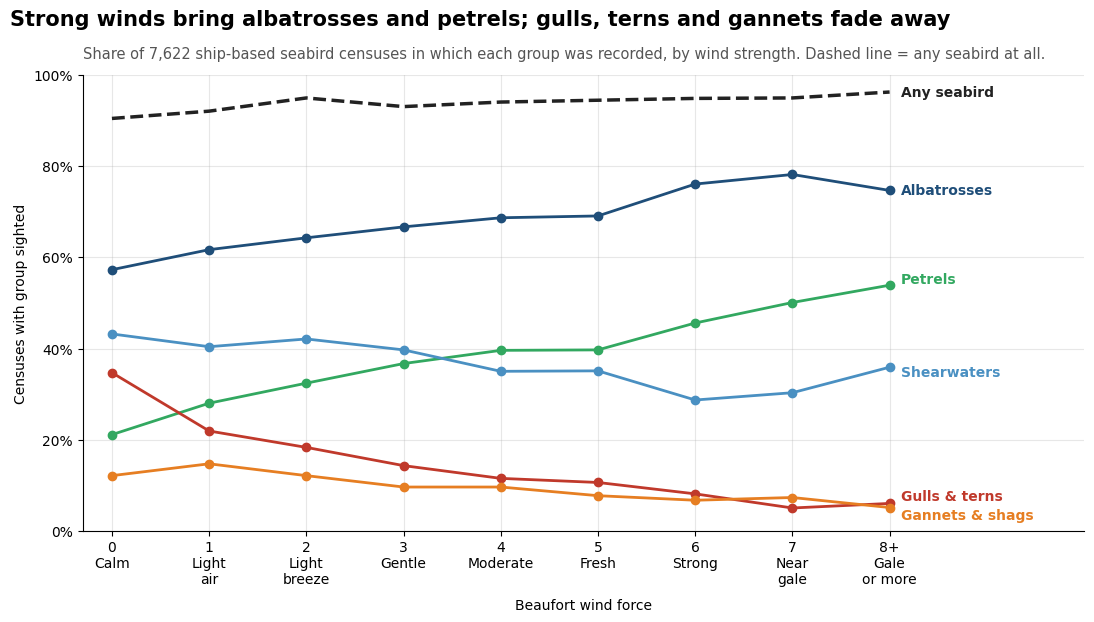

In [103]:
groups = {  # group: (colour, label y-offset in points)
    'Albatrosses':     ('#1f4e79', 0),
    'Petrels':         ('#32a860', 4),
    'Shearwaters':     ('#4a90c2', -4),
    'Gulls & terns':   ('#c0392b', 5),
    'Gannets & shags': ('#e67e22', -6),
}
wind_labels = ['Calm', 'Light\nair', 'Light\nbreeze', 'Gentle', 'Moderate',
               'Fresh', 'Strong', 'Near\ngale', 'Gale\nor more']

fig, ax = plt.subplots(figsize=(11, 6.5))

# Overall reference line: any seabird at all
ax.plot(overall_rate.index, overall_rate, color='#222222', linewidth=2.5, linestyle='--')
ax.annotate('Any seabird', (overall_rate.index[-1], overall_rate.iloc[-1]),
            xytext=(8, 0), textcoords='offset points', va='center',
            color='#222222', fontweight='bold')

for g, (colour, dy) in groups.items():
    ax.plot(sighting_rate.index, sighting_rate[g], marker='o', markersize=6,
            color=colour, linewidth=2)
    ax.annotate(g, (sighting_rate.index[-1], sighting_rate[g].iloc[-1]),
                xytext=(8, dy), textcoords='offset points', va='center',
                color=colour, fontweight='bold')

ax.set_xticks(range(9), [f'{i}\n{lab}' if i < 8 else f'8+\n{lab}'
                         for i, lab in enumerate(wind_labels)])
ax.set_xlim(-0.3, 10)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(lambda y, _: f'{y:.0f}%')
ax.set_xlabel('Beaufort wind force', labelpad=8)
ax.set_ylabel('Censuses with group sighted')
ax.spines[['top', 'right']].set_visible(False)
ax.grid( alpha=0.3)

fig.suptitle('Strong winds bring albatrosses and petrels; gulls, terns and gannets fade away',
             x=0.01, ha='left', fontsize=15, fontweight='bold')
ax.set_title(f'Share of {len(censuses):,} ship-based seabird censuses in which each group '
             'was recorded, by wind strength. Dashed line = any seabird at all.',
             loc='left', fontsize=10.5, color='#555555', pad=12)

plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

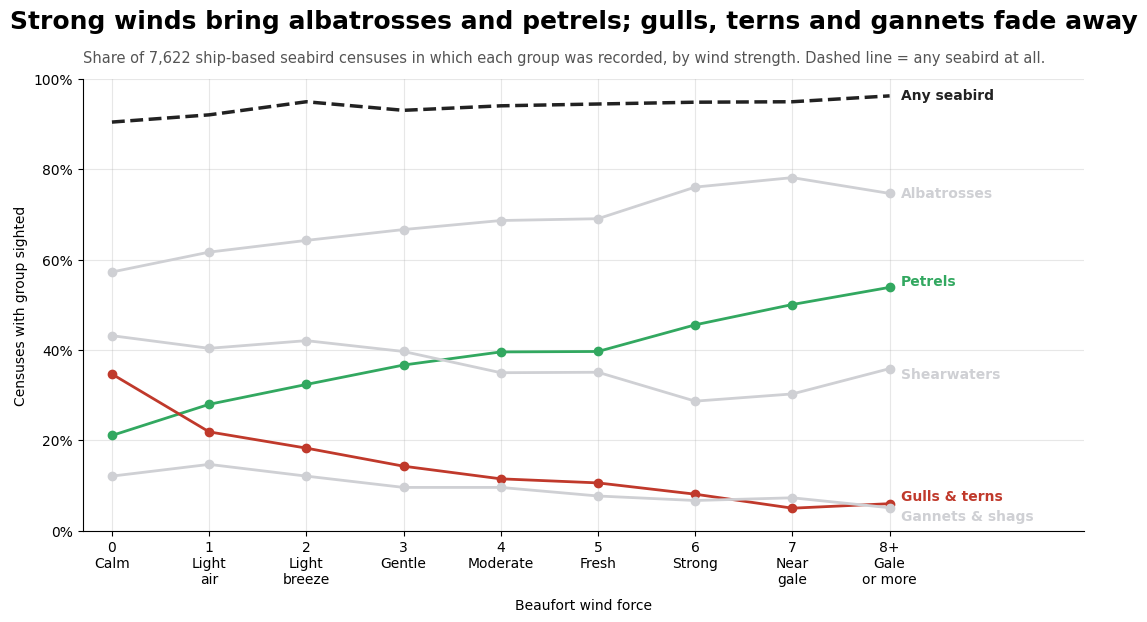

In [105]:
groups = {  # group: (colour, label y-offset in points)
    'Albatrosses':     ('#cfd0d4', 0),
    'Petrels':         ('#32a860', 4),
    'Shearwaters':     ('#cfd0d4', -4),
    'Gulls & terns':   ('#c0392b', 5),
    'Gannets & shags': ('#cfd0d4', -6),
}
wind_labels = ['Calm', 'Light\nair', 'Light\nbreeze', 'Gentle', 'Moderate',
               'Fresh', 'Strong', 'Near\ngale', 'Gale\nor more']

fig, ax = plt.subplots(figsize=(11, 6.5))

# Overall reference line: any seabird at all
ax.plot(overall_rate.index, overall_rate, color='#222222', linewidth=2.5, linestyle='--')
ax.annotate('Any seabird', (overall_rate.index[-1], overall_rate.iloc[-1]),
            xytext=(8, 0), textcoords='offset points', va='center',
            color='#222222', fontweight='bold')

for g, (colour, dy) in groups.items():
    ax.plot(sighting_rate.index, sighting_rate[g], marker='o', markersize=6,
            color=colour, linewidth=2)
    ax.annotate(g, (sighting_rate.index[-1], sighting_rate[g].iloc[-1]),
                xytext=(8, dy), textcoords='offset points', va='center',
                color=colour, fontweight='bold')

ax.set_xticks(range(9), [f'{i}\n{lab}' if i < 8 else f'8+\n{lab}'
                         for i, lab in enumerate(wind_labels)])
ax.set_xlim(-0.3, 10)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(lambda y, _: f'{y:.0f}%')
ax.set_xlabel('Beaufort wind force', labelpad=8)
ax.set_ylabel('Censuses with group sighted')
ax.spines[['top', 'right']].set_visible(False)
ax.grid( alpha=0.3)

fig.suptitle('Strong winds bring albatrosses and petrels; gulls, terns and gannets fade away',
             x=0.01, ha='left', fontsize=18, fontweight='bold')
ax.set_title(f'Share of {len(censuses):,} ship-based seabird censuses in which each group '
             'was recorded, by wind strength. Dashed line = any seabird at all.',
             loc='left', fontsize=10.5, color='#555555', pad=12)

plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()